In [14]:
# ============================================================
# 03 — BASELINE MODELS
# Gas Turbine Energy Yield and Emissions
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Change to Path("data") if running from the project root
DATA_DIR = Path("../data")

files = sorted(DATA_DIR.glob("gt_*.csv"))

if not files:
    raise FileNotFoundError(
        f"No gt_*.csv files found in {DATA_DIR.resolve()}"
    )

frames = []

for file in files:
    df = pd.read_csv(file)
    df["Year"] = int(file.stem.split("_")[-1])
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

feature_cols = [
    "AT", "AP", "AH", "AFDP",
    "GTEP", "TIT", "TAT", "CDP"
]

target_cols = ["TEY", "CO", "NOX"]

print("Dataset shape:", data.shape)
print("Years:", sorted(data["Year"].unique()))
print("Features:", feature_cols)
print("Targets:", target_cols)

display(data.head())

Dataset shape: (36733, 12)
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]
Features: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'CDP']
Targets: ['TEY', 'CO', 'NOX']


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


In [15]:
# ============================================================
# TEMPORAL TRAIN / TEST SPLIT
# ============================================================

train_data = data[data["Year"] <= 2014].copy()
test_data = data[data["Year"] == 2015].copy()

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]

Y_train = train_data[target_cols]
Y_test = test_data[target_cols]

print("Training observations:", len(train_data))
print("Test observations:", len(test_data))

print("\nTraining years:", sorted(train_data["Year"].unique()))
print("Test years:", sorted(test_data["Year"].unique()))

assert set(train_data["Year"]).isdisjoint(set(test_data["Year"]))
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

Training observations: 29349
Test observations: 7384

Training years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
Test years: [np.int64(2015)]


In [16]:
# ============================================================
# EVALUATION METRICS
# ============================================================

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

In [17]:
# ============================================================
# RIDGE HYPERPARAMETER SELECTION
# ============================================================

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

alpha_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Training data are ordered by year and original row order.
tscv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=alpha_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
    refit=True
)

ridge_search.fit(X_train, Y_train["TEY"])

print("Selected alpha for TEY:", ridge_search.best_params_)
print("Best CV RMSE for TEY:", -ridge_search.best_score_)

Selected alpha for TEY: {'model__alpha': 100.0}
Best CV RMSE for TEY: 1.0947593961219657


In [18]:
# ============================================================
# TUNE RIDGE SEPARATELY FOR EACH TARGET
# ============================================================

ridge_models = {}
ridge_cv_results = {}

for target in target_cols:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"model__alpha": alpha_grid["model__alpha"]},
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, Y_train[target])

    ridge_models[target] = search.best_estimator_
    ridge_cv_results[target] = {
        "Best_Alpha": search.best_params_["model__alpha"],
        "CV_RMSE": -search.best_score_
    }

display(pd.DataFrame(ridge_cv_results).T)

,Best_Alpha,CV_RMSE
TEY,100.0,1.094759
CO,100.0,1.701667
NOX,10.0,9.517881


In [ ]:
# ============================================================
# FIT BASELINE MODELS
# ============================================================

models = {
    "Mean Predictor": {},
    "Linear Regression": {},
    "Ridge Regression": ridge_models
}

for target in target_cols:
    # Baseline 1: mean prediction
    mean_model = DummyRegressor(strategy="mean")
    mean_model.fit(X_train, Y_train[target])

    # Baseline 2: ordinary least squares
    linear_model = LinearRegression()
    linear_model.fit(X_train, Y_train[target])

    models["Mean Predictor"][target] = mean_model
    models["Linear Regression"][target] = linear_model

print("All baseline models trained.")

All baseline models trained.
{'Mean Predictor': {'TEY': DummyRegressor(), 'CO': DummyRegressor(), 'NOX': DummyRegressor()}, 'Linear Regression': {'TEY': LinearRegression(), 'CO': LinearRegression(), 'NOX': LinearRegression()}, 'Ridge Regression': {'TEY': Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=100.0))]), 'CO': Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=100.0))]), 'NOX': Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=10.0))])}}


In [20]:
# ============================================================
# TEMPORAL TEST EVALUATION
# ============================================================

temporal_results = []
temporal_predictions = {}

for model_name, target_models in models.items():
    for target in target_cols:
        model = target_models[target]

        predictions = model.predict(X_test)

        temporal_predictions[(model_name, target)] = predictions

        metrics = calculate_metrics(Y_test[target], predictions)

        temporal_results.append({
            "Model": model_name,
            "Target": target,
            **metrics
        })

temporal_results_df = pd.DataFrame(temporal_results)

print("========== 2015 TEST RESULTS ==========")
display(
    temporal_results_df
    .sort_values(["Target", "RMSE"])
    .round(4)
)

========== 2015 TEST RESULTS ==========


,Model,Target,MAE,RMSE,R2
7,Ridge Regression,CO,1.3388,1.8881,0.2862
4,Linear Regression,CO,1.3670,1.9241,0.2587
1,Mean Predictor,CO,1.3919,2.4276,-0.1800
5,Linear Regression,NOX,8.1810,10.2146,0.1580
8,Ridge Regression,NOX,8.2403,10.2731,0.1483
2,Mean Predictor,NOX,11.1144,13.0245,-0.3690
3,Linear Regression,TEY,1.2831,1.7910,0.9877
6,Ridge Regression,TEY,1.4627,2.0296,0.9843
0,Mean Predictor,TEY,12.9453,16.1896,-0.0014


In [21]:
# ============================================================
# RANDOM-SPLIT BENCHMARK
# ============================================================

X_random_train, X_random_test, Y_random_train, Y_random_test = (
    train_test_split(
        data[feature_cols],
        data[target_cols],
        test_size=0.20,
        random_state=RANDOM_STATE
    )
)

random_results = []

for target in target_cols:
    random_models = {
        "Mean Predictor": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=ridge_models[target]
                            .named_steps["model"].alpha))
        ])
    }

    for model_name, model in random_models.items():
        model.fit(X_random_train, Y_random_train[target])

        pred = model.predict(X_random_test)

        random_results.append({
            "Model": model_name,
            "Target": target,
            **calculate_metrics(Y_random_test[target], pred)
        })

random_results_df = pd.DataFrame(random_results)

print("========== RANDOM-SPLIT RESULTS ==========")
display(
    random_results_df
    .sort_values(["Target", "RMSE"])
    .round(4)
)

========== RANDOM-SPLIT RESULTS ==========


,Model,Target,MAE,RMSE,R2
4,Linear Regression,CO,0.8656,1.5651,0.5495
5,Ridge Regression,CO,0.8651,1.5655,0.5493
3,Mean Predictor,CO,1.4150,2.3319,-0.0000
8,Ridge Regression,NOX,6.1150,8.3773,0.4704
7,Linear Regression,NOX,6.1139,8.3807,0.4700
6,Mean Predictor,NOX,8.8370,11.5119,-0.0001
1,Linear Regression,TEY,0.7725,0.9804,0.9961
2,Ridge Regression,TEY,0.7882,1.0065,0.9958
0,Mean Predictor,TEY,11.5130,15.6118,-0.0001


In [22]:
# ============================================================
# COMPARE EVALUATION STRATEGIES
# ============================================================

temporal_comparison = temporal_results_df.copy()
temporal_comparison["Split"] = "Temporal: test on 2015"

random_comparison = random_results_df.copy()
random_comparison["Split"] = "Random: 80/20"

comparison = pd.concat(
    [temporal_comparison, random_comparison],
    ignore_index=True
)

display(
    comparison[
        ["Split", "Model", "Target", "MAE", "RMSE", "R2"]
    ].sort_values(["Target", "Model", "Split"]).round(4)
)

,Split,Model,Target,MAE,RMSE,R2
13,Random: 80/20,Linear Regression,CO,0.8656,1.5651,0.5495
4,Temporal: test on 2015,Linear Regression,CO,1.3670,1.9241,0.2587
12,Random: 80/20,Mean Predictor,CO,1.4150,2.3319,-0.0000
1,Temporal: test on 2015,Mean Predictor,CO,1.3919,2.4276,-0.1800
14,Random: 80/20,Ridge Regression,CO,0.8651,1.5655,0.5493
7,Temporal: test on 2015,Ridge Regression,CO,1.3388,1.8881,0.2862
16,Random: 80/20,Linear Regression,NOX,6.1139,8.3807,0.4700
5,Temporal: test on 2015,Linear Regression,NOX,8.1810,10.2146,0.1580
15,Random: 80/20,Mean Predictor,NOX,8.8370,11.5119,-0.0001
2,Temporal: test on 2015,Mean Predictor,NOX,11.1144,13.0245,-0.3690


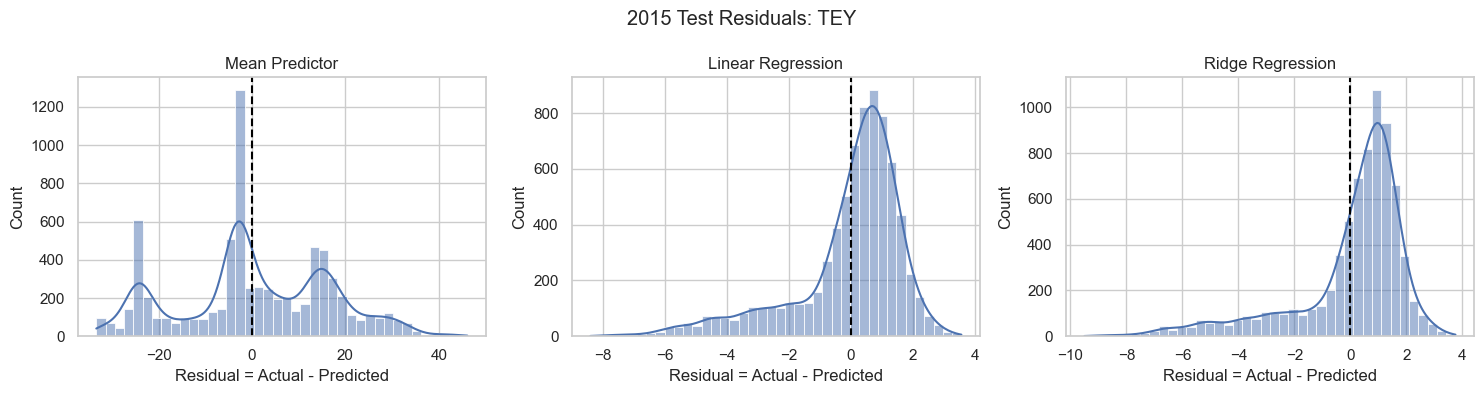

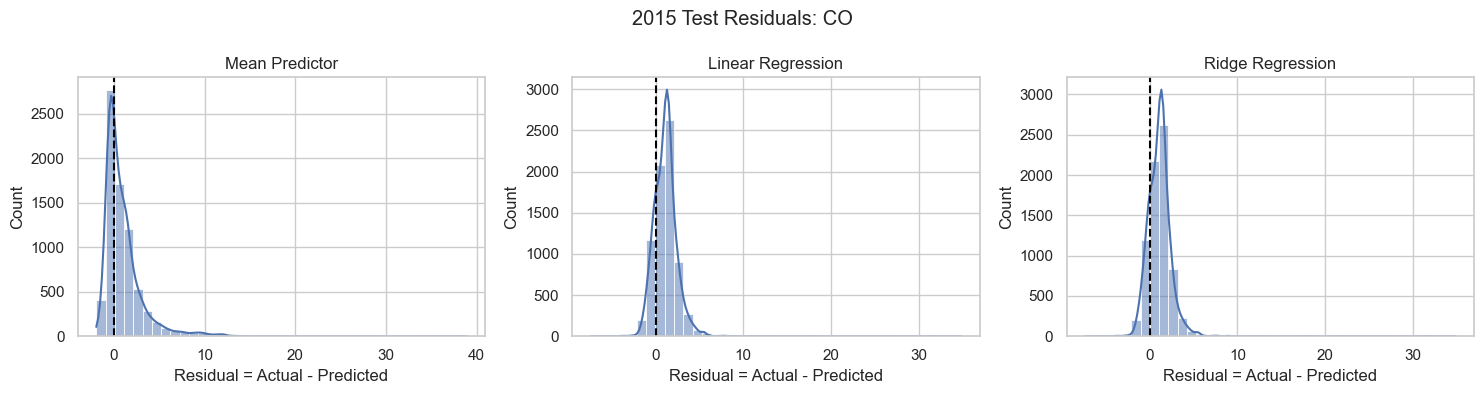

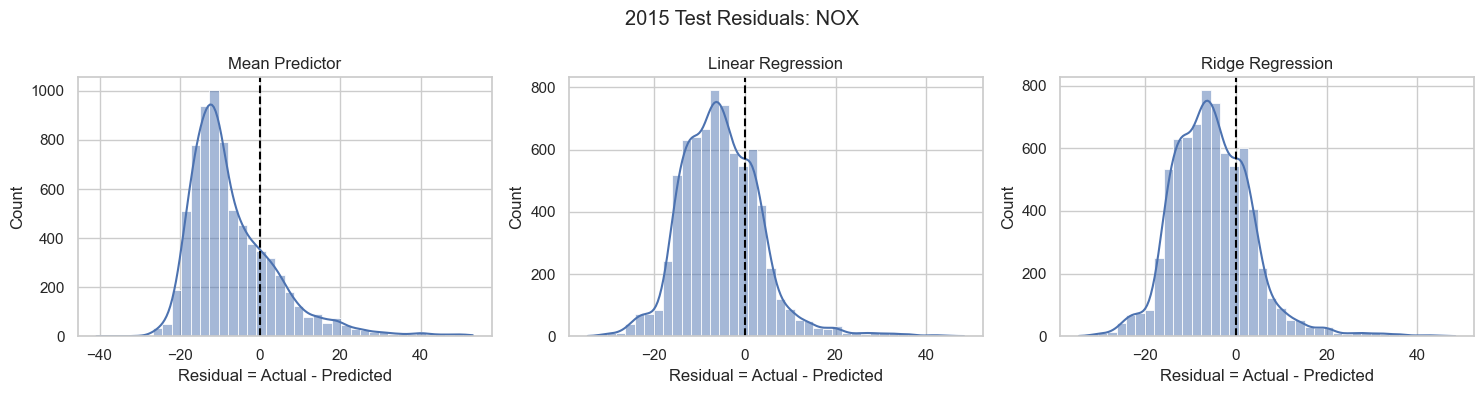

In [23]:
# ============================================================
# RESIDUAL HISTOGRAMS
# ============================================================

for target in target_cols:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, model_name in zip(axes, models.keys()):
        pred = temporal_predictions[(model_name, target)]
        residuals = Y_test[target].to_numpy() - pred

        sns.histplot(
            residuals,
            bins=40,
            kde=True,
            ax=ax
        )

        ax.axvline(0, linestyle="--", color="black")
        ax.set_title(model_name)
        ax.set_xlabel("Residual = Actual - Predicted")

    fig.suptitle(f"2015 Test Residuals: {target}")
    plt.tight_layout()
    plt.show()

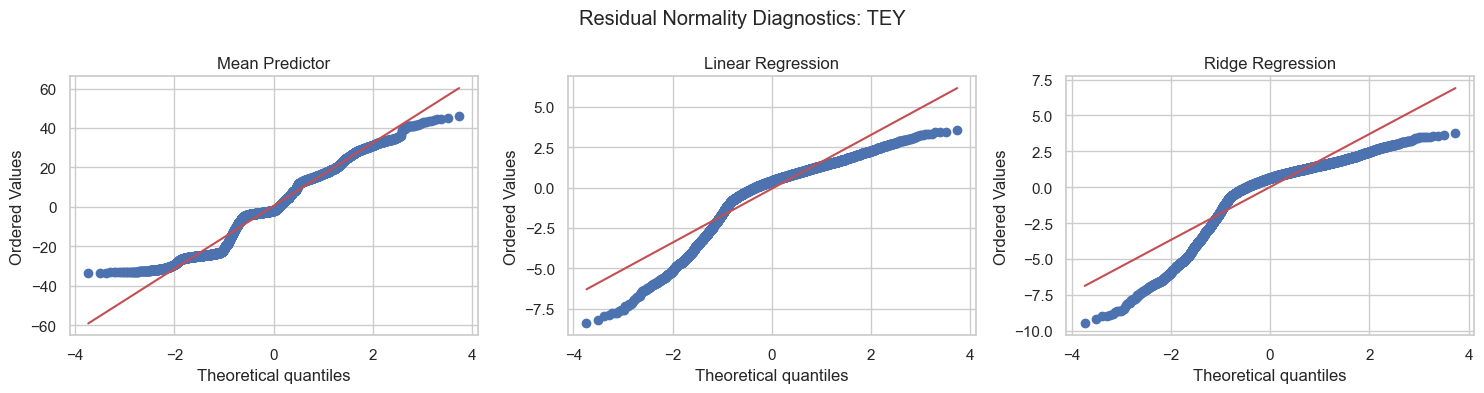

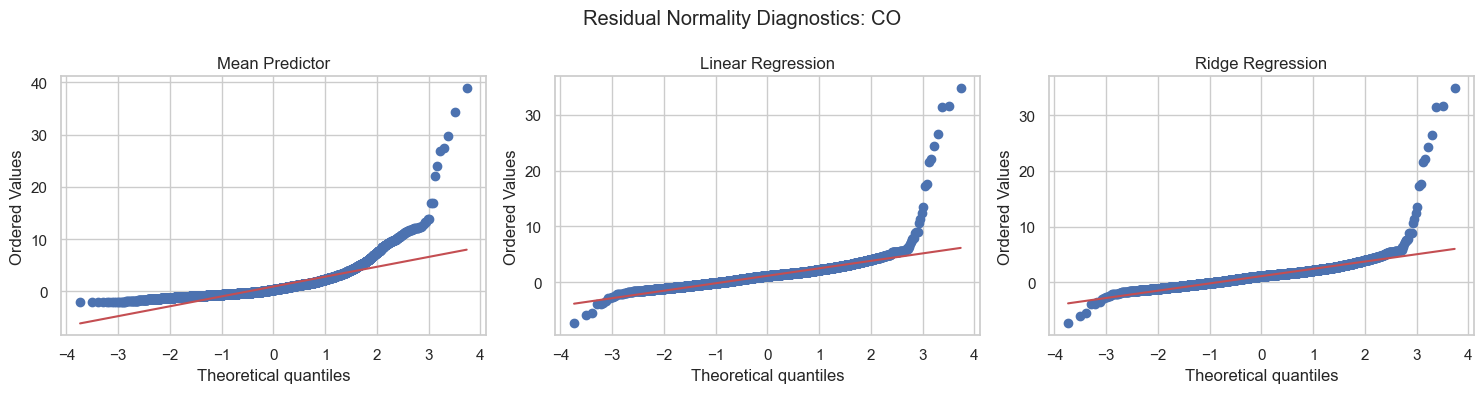

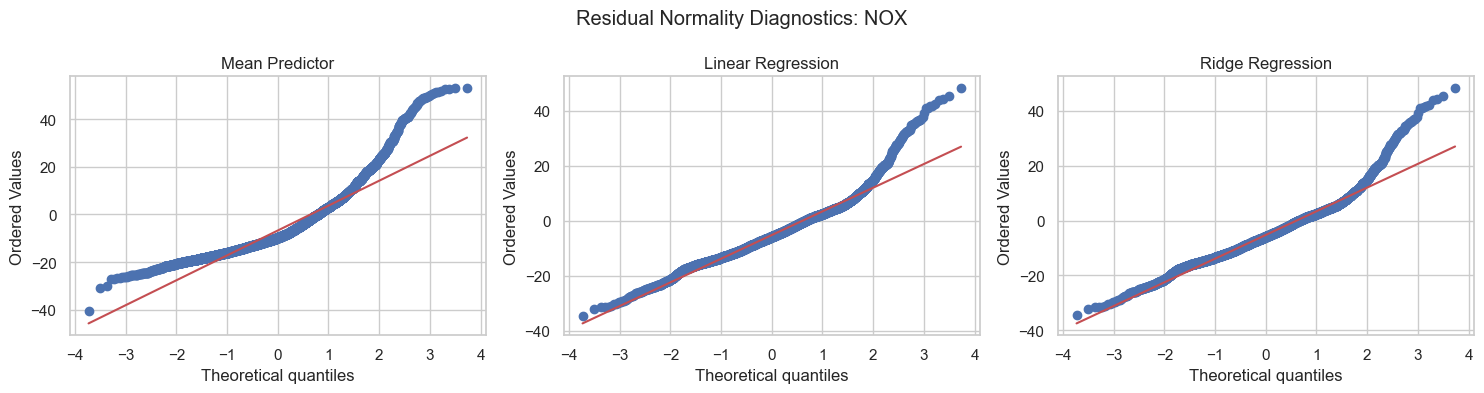

In [24]:
# ============================================================
# RESIDUAL Q-Q PLOTS
# ============================================================

for target in target_cols:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, model_name in zip(axes, models.keys()):
        pred = temporal_predictions[(model_name, target)]
        residuals = Y_test[target].to_numpy() - pred

        stats.probplot(
            residuals,
            dist="norm",
            plot=ax
        )

        ax.set_title(model_name)

    fig.suptitle(f"Residual Normality Diagnostics: {target}")
    plt.tight_layout()
    plt.show()

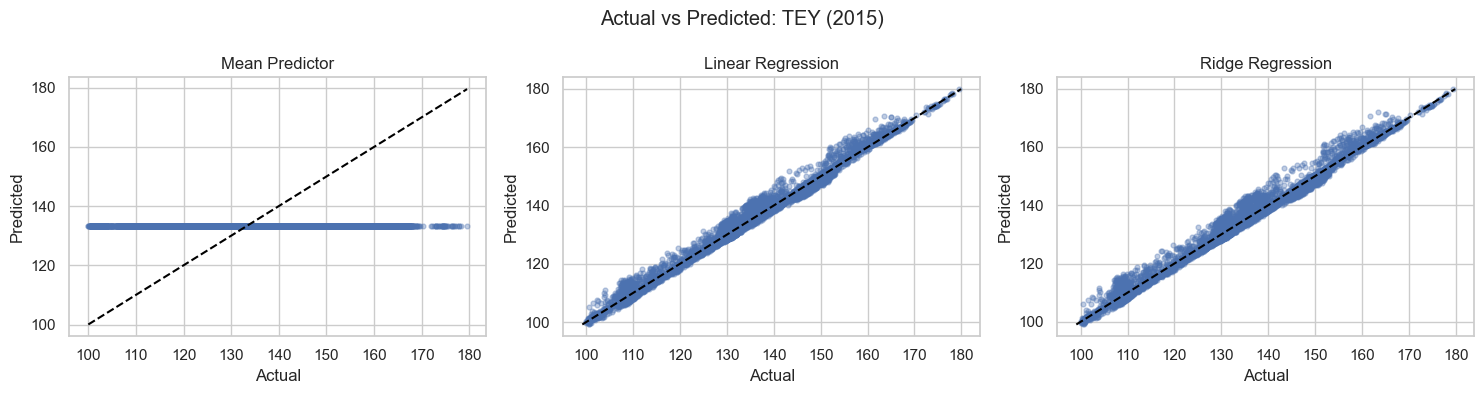

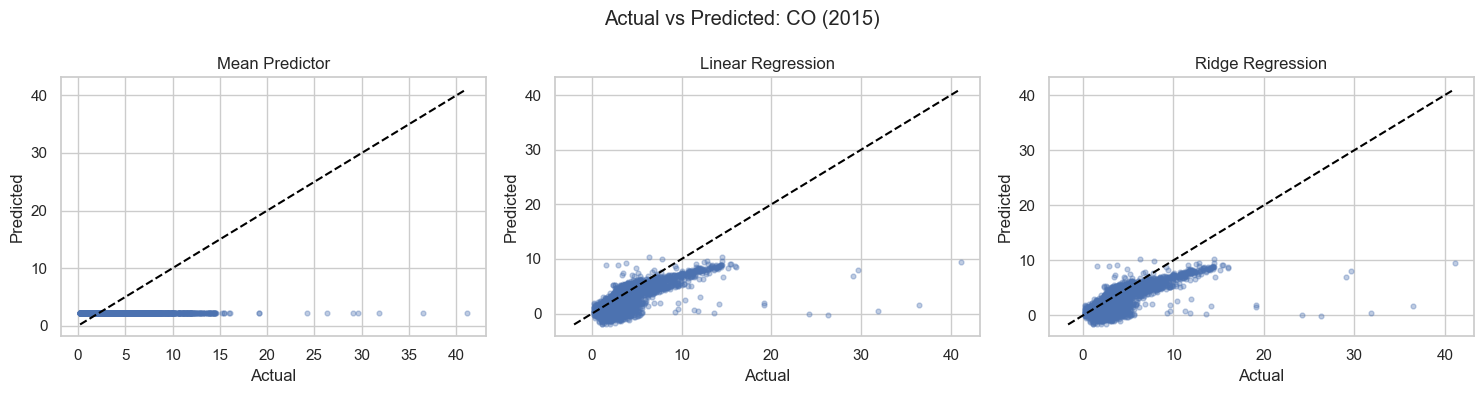

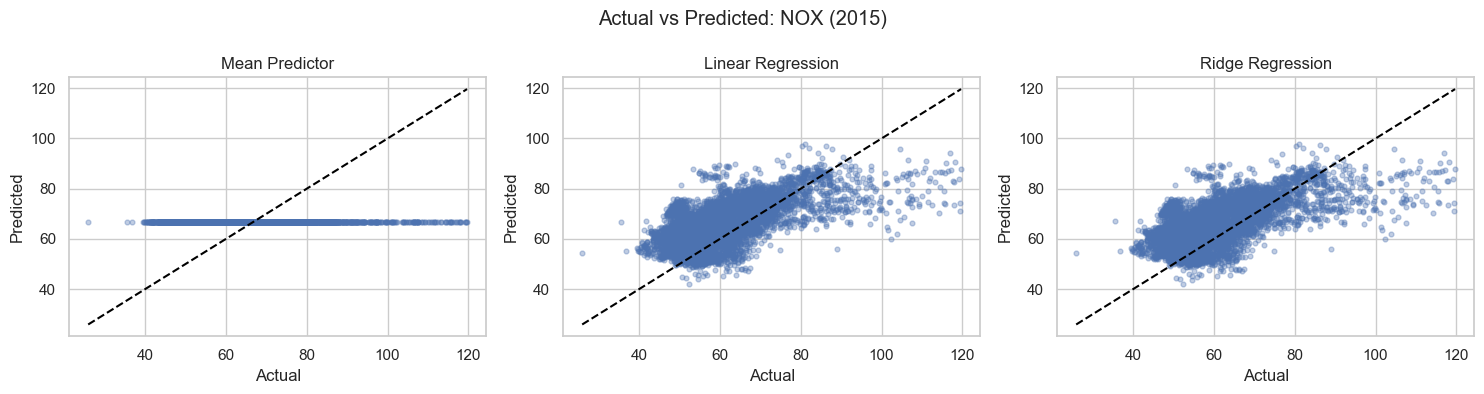

In [25]:
# ============================================================
# ACTUAL VS PREDICTED VALUES
# ============================================================

for target in target_cols:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    actual = Y_test[target].to_numpy()

    for ax, model_name in zip(axes, models.keys()):
        pred = temporal_predictions[(model_name, target)]

        ax.scatter(actual, pred, alpha=0.35, s=12)

        lower = min(actual.min(), pred.min())
        upper = max(actual.max(), pred.max())

        ax.plot(
            [lower, upper],
            [lower, upper],
            linestyle="--",
            color="black"
        )

        ax.set_xlabel("Actual")
        ax.set_ylabel("Predicted")
        ax.set_title(model_name)

    fig.suptitle(f"Actual vs Predicted: {target} (2015)")
    plt.tight_layout()
    plt.show()

In [26]:
# ============================================================
# SAVE RESULTS
# ============================================================

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

temporal_results_df.to_csv(
    OUTPUT_DIR / "baseline_temporal_results.csv",
    index=False
)

random_results_df.to_csv(
    OUTPUT_DIR / "baseline_random_results.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "baseline_split_comparison.csv",
    index=False
)

prediction_output = test_data[["Year"]].copy()

for target in target_cols:
    prediction_output[f"{target}_actual"] = Y_test[target].values

    for model_name in models:
        safe_name = model_name.lower().replace(" ", "_")
        prediction_output[
            f"{target}_{safe_name}_pred"
        ] = temporal_predictions[(model_name, target)]

prediction_output.to_csv(
    OUTPUT_DIR / "baseline_2015_predictions.csv",
    index=False
)

print("Baseline results and predictions saved to:", OUTPUT_DIR.resolve())

Baseline results and predictions saved to: C:\Users\devra\Music\gas-turbine-ml\outputs
